# استكشاف بيانات صوت العميل
**Wadeen Khalid Al adwani** · SDAIA Academy · instructor: مضر محمد الفضلي

استكشاف تعليمي للبيانات المؤلفة وحدودها؛ لا يمثل توزيع العملاء الحقيقي. دفتر التجربة الكامل موجود في جذر المستودع.

In [1]:
from pathlib import Path
import os, sys, json, subprocess
ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
assert (ROOT / "data/feedback.csv").exists(), "Run from the project root or notebooks/"
os.environ.setdefault("MPLCONFIGDIR", "/tmp/voice_of_customer-matplotlib")
os.environ.setdefault("XDG_CACHE_HOME", "/workspace/.cache")
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
from IPython.display import display, Markdown
from voice_of_customer.pipeline import load_analyzer
from voice_of_customer.text import normalize
data = pd.read_csv(ROOT / "data/feedback.csv")
display(data.groupby(["split", "lang", "label"]).size().rename("n").to_frame())
assert not data.text.map(normalize).duplicated().any()

n
split      lang label       
test       ar   negative  20
                neutral   20
                positive  20
           en   negative   2
                neutral    2
                positive   2
train      ar   negative  30
                neutral   30
                positive  30
           en   negative   4
                neutral    4
                positive   4
validation ar   negative  10
                neutral   10
                positive  10

In [2]:
data["characters"] = data.text.str.len()
display(data.groupby(["split", "dialect"]).agg(n=("id", "count"), mean_chars=("characters", "mean")))
display(data.groupby(["split", "phenomenon"]).size().rename("n").to_frame())

n  mean_chars
split      dialect                
test       english   6   35.666667
           gulf     30   29.633333
           msa      30   34.266667
train      english  12   35.666667
           gulf     45   23.533333
           msa      45   29.866667
validation gulf     15   23.600000
           msa      15   27.933333

n
split      phenomenon                
test       dialect                  4
           insufficient_evidence    4
           mixed                    5
           negation                 7
           ordinary                33
           question                 7
           sarcasm                  6
train      ordinary               102
validation ordinary                30

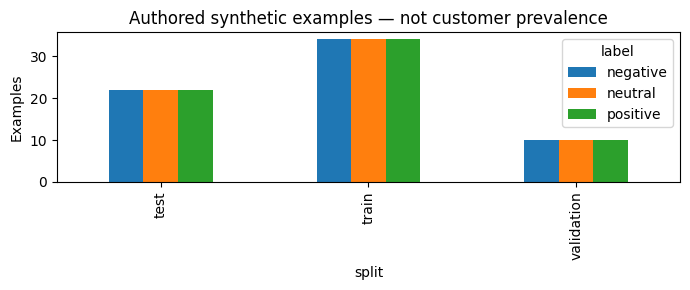

In [3]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 3))
data.groupby(["split", "label"]).size().unstack().plot.bar(ax=ax)
ax.set(title="Authored synthetic examples — not customer prevalence", ylabel="Examples")
plt.tight_layout()
plt.show()

## ملاحظات
- كل فئة متوازنة في كل split؛ الواقع قد يكون غير متوازن.
- validation عربية فقط؛ الإنجليزية exploratory.
- اختبارنا أصعب عمدًا ويشمل السخرية والنفي؛ المقاييس ليست تقديرًا عامًا لأداء العملاء.
- الخطوة التالية: بيانات مرخصة جديدة، تدقيق PII مستقل، مراجعة تسميات ومجموعات لمنع تسرب المؤلف/المصدر.